# APID 22 exploration

After APID 2 (housekeeping, see `APID_2.ipynb`), APID 22 is the next big one: 11 186 packets of 0.3 to 1.5 kB.
Questions, same as before:

1. How is a packet laid out, and what is inside?
2. What is the cadence, and how do the packets relate to each other?
3. Does it look like **LYRA** (up to 100 Hz sampling, 4 channels per unit, raw counts), or something else?
4. Anything that tells where the Sun is?

In [55]:
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from cadu import iter_packets, packet_apid, packet_sequence_count

In [56]:
CADU_DIR = Path("cadus")
APID = 22

# Layout of a packet, as found below. It is the same header as the APID 2 reports: 6 byte primary header, a PUS-like
# secondary header of 3 bytes, a 2 byte marker, a tick counter with a fraction, then 4 zero bytes, the length of the
# data and the data. The last 2 bytes are a CRC.
SECONDARY_HEADER = bytes.fromhex("10088e")
MARKER = b"\x00\x01"
TIME_OFFSET = 11
LENGTH_OFFSET = 21
DATA_OFFSET = 23
CRC_LEN = 2
SECONDS_PER_TICK = 1.0  # ticks are seconds, see APID_18.ipynb

## 1. Load

In [57]:
packets: list[tuple[str, int, bytes]] = []  # (file name, vcid, packet)
for path in sorted(CADU_DIR.glob("*.cadu")):
    packets += [(path.name, vcid, packet) for vcid, packet in iter_packets(path) if packet_apid(packet) == APID]
    print(f"processed {path.name}")

print(f"{len(packets)} packets with APID {APID}")
print("per file:", dict(Counter(name for name, _, _ in packets)))
print("per virtual channel:", dict(Counter(vcid for _, vcid, _ in packets)))

processed proba2_dump(1).cadu
processed proba2_dump(10).cadu
processed proba2_dump(11).cadu
processed proba2_dump(12).cadu
processed proba2_dump(2).cadu
processed proba2_dump(3).cadu
processed proba2_dump(4).cadu
processed proba2_dump(5).cadu
processed proba2_dump(6).cadu
processed proba2_dump(7).cadu
processed proba2_dump(8).cadu
processed proba2_dump(9).cadu
processed proba2_dump.cadu
processed proba2_dump_aug_12_eclipse.cadu
11186 packets with APID 22
per file: {'proba2_dump(11).cadu': 286, 'proba2_dump(12).cadu': 289, 'proba2_dump(2).cadu': 4340, 'proba2_dump(3).cadu': 271, 'proba2_dump(4).cadu': 68, 'proba2_dump(5).cadu': 94, 'proba2_dump(6).cadu': 5688, 'proba2_dump(7).cadu': 150}
per virtual channel: {1: 1551, 2: 9632, 0: 1, 5: 1, 6: 1}


## 2. Headers

In [58]:
print("sequence flags:", Counter(packet[2] >> 6 for _, _, packet in packets))
print("bytes 6-8:", Counter(packet[6:9].hex() for _, _, packet in packets).most_common(3))

# Everything without the usual secondary header was reassembled across lost frames and is garbage.
reports = [(name, vcid, packet) for name, vcid, packet in packets if packet[6:9] == SECONDARY_HEADER]
print(f"{len(reports)} packets with the usual header")

sequence flags: Counter({3: 11186})
bytes 6-8: [('10088e', 11170), ('58c797', 1), ('567a84', 1)]
11170 packets with the usual header


distinct lengths: 215
most common: [(333, 5239), (1321, 627), (1337, 597), (317, 590), (1329, 499), (1345, 297), (1453, 253), (1449, 250)]


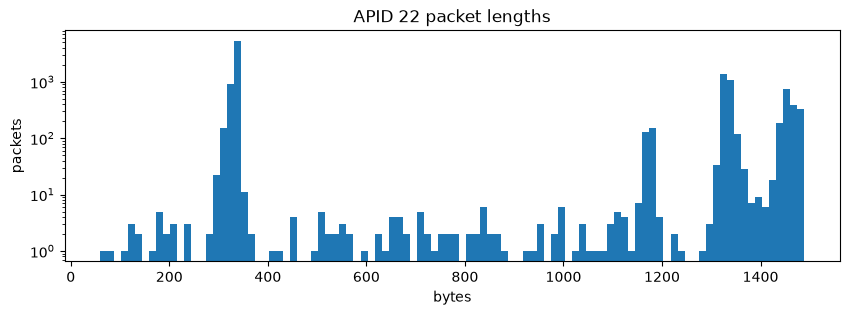

In [59]:
lengths = Counter(len(packet) for _, _, packet in reports)
print("distinct lengths:", len(lengths))
print("most common:", lengths.most_common(8))

fig, ax = plt.subplots(figsize=(10, 3))
ax.hist([len(packet) for _, _, packet in reports], bins=100)
ax.set(yscale="log", title="APID 22 packet lengths", xlabel="bytes", ylabel="packets")
plt.show()

The lengths vary a lot (215 distinct values), so the data is not a fixed-size record. Check the two bytes at 21-22
and the last two bytes against that.

In [60]:
declared = np.array([int.from_bytes(packet[LENGTH_OFFSET : LENGTH_OFFSET + 2]) for _, _, packet in reports])
actual = np.array([len(packet) for _, _, packet in reports])
print("length - declared data length:", Counter(actual - declared).most_common(4))
print("= header (23) + CRC (2) in", f"{np.mean(actual - declared == DATA_OFFSET + CRC_LEN):.1%}")


def crc16(data: bytes) -> int:
    """CRC-16/CCITT-FALSE."""
    crc = 0xFFFF
    for byte in data:
        crc ^= byte << 8
        for _ in range(8):
            crc = ((crc << 1) ^ 0x1021) & 0xFFFF if crc & 0x8000 else (crc << 1) & 0xFFFF
    return crc


crc_ok = np.array([crc16(packet[:-CRC_LEN]) == int.from_bytes(packet[-CRC_LEN:]) for _, _, packet in reports])
print(f"CRC-16 over the whole packet, header included, matches in {crc_ok.mean():.1%} of the packets")

length - declared data length: [(np.int64(25), 11137), (np.int64(-125), 2), (np.int64(-195), 2), (np.int64(-181), 1)]
= header (23) + CRC (2) in 99.7%
CRC-16 over the whole packet, header included, matches in 99.0% of the packets


The data length at 21-22 is the packet length minus 25, and the last 2 bytes are a CRC-16/CCITT over the whole
packet. The dumps are not Reed-Solomon corrected, so the packets which fail the CRC have bit errors; drop them for
any analysis that needs exact values.

In [61]:
good = [report for report, ok in zip(reports, crc_ok, strict=True) if ok]
print(f"{len(good)} packets with a valid CRC")

11055 packets with a valid CRC


## 3. Time and cadence

Same time field as APID 2: a 32 bit tick counter at 11 and a 16 bit fraction after it.

In [62]:
runs: dict[tuple[str, int], list[tuple[int, int, bytes]]] = defaultdict(list)  # (file, vc) -> (tick, seq, packet)
for name, vcid, packet in good:
    tick = int.from_bytes(packet[TIME_OFFSET : TIME_OFFSET + 4])
    runs[name, vcid].append((tick, packet_sequence_count(packet), packet))

steps = Counter()
for run in runs.values():
    ticks = [tick for tick, _, _ in run]
    steps.update(np.diff(ticks))
print("tick steps between consecutive packets:", steps.most_common(6))
total = sum(steps.values())
print(f"-> one packet per tick in {steps[1] / total:.1%}, i.e. one every {SECONDS_PER_TICK} s")

sequence_steps = Counter()
for run in runs.values():
    sequence_steps.update(np.diff([seq for _, seq, _ in run]) % (1 << 14))
print("sequence count steps:", sequence_steps.most_common(4))

tick steps between consecutive packets: [(np.int64(1), 10968), (np.int64(2), 26), (np.int64(3), 12), (np.int64(6), 11), (np.int64(7), 6), (np.int64(4), 5)]
-> one packet per tick in 99.3%, i.e. one every 1.0 s
sequence count steps: [(np.int64(1), 10974), (np.int64(2), 22), (np.int64(3), 12), (np.int64(6), 11)]


In [63]:
spans = []
for (name, vcid), run in sorted(runs.items()):
    ticks = np.array([tick for tick, _, _ in run])
    breaks = np.nonzero(np.diff(ticks) > 1)[0]
    contiguous = np.diff(np.concatenate([[-1], breaks, [len(ticks) - 1]]))
    spans.append((name, vcid, len(run), len(breaks), contiguous.max()))
print(f"{'file':24s} vc packets gaps longest run")
for name, vcid, count, gaps, longest in spans:
    print(f"{name:24s} {vcid:2d} {count:7d} {gaps:4d} {longest:7d}")

file                     vc packets gaps longest run
proba2_dump(11).cadu      1     281    7     129
proba2_dump(12).cadu      1     277    7     179
proba2_dump(2).cadu       1     113    3      98
proba2_dump(2).cadu       2    4133   32    1161
proba2_dump(3).cadu       1     269    2     267
proba2_dump(4).cadu       1      66    5      21
proba2_dump(5).cadu       1      92    5      29
proba2_dump(6).cadu       1     276    7     217
proba2_dump(6).cadu       2    5407    3    4592
proba2_dump(7).cadu       1     141    6      85


## 4. The data field

Look at the data as big-endian int16. Packets seem to be cut from a stream of self-described blocks ("chunks"):
the first word of a chunk is its size in bytes (154 or 162), followed by an index and more header words.

In [64]:
CHUNK_SIZES = (154, 162)
HEADER_WORDS = 6
SOURCE_IDS = (49, 50)  # header word 4
FLAG_MASK = 0x00F7  # low byte of header word 5 is 0x05 or 0x0D, the bit with value 8 flips from chunk to chunk
FLAG_VALUE = 0x0005


def find_chunks(data: bytes) -> list[int]:
    """Offsets of the chunks in a data field. Looks for a plausible header at every byte offset.

    The size alone is not enough: a sample can be 154 as well. Words 4 and 5 are checked too.
    """
    offsets = []
    position = 0
    while position + 2 * HEADER_WORDS <= len(data):
        size, source, flags = (int.from_bytes(data[position + i : position + i + 2]) for i in (0, 8, 10))
        if (
            size in CHUNK_SIZES
            and source in SOURCE_IDS
            and flags & FLAG_MASK == FLAG_VALUE
            and position + size <= len(data)
        ):
            offsets.append(position)
            position += size
        else:
            position += 1
    return offsets


first_chunk = Counter()
for _, _, packet in good:
    offsets = find_chunks(packet[DATA_OFFSET:-CRC_LEN])
    first_chunk[offsets[0] if offsets else None] += 1
print("offset of the first chunk in the data field:", first_chunk.most_common(8))

offset of the first chunk in the data field: [(0, 5877), (4, 451), (2, 447), (None, 364), (98, 121), (74, 115), (84, 113), (114, 109)]


In [65]:
data = good[1000][2][DATA_OFFSET:-CRC_LEN]
words = np.frombuffer(data[: len(data) // 2 * 2], dtype=">i2")
print(f"a packet of {len(good[1000][2])} bytes, int16 words in rows of 8:")
for row in range(0, min(len(words), 96), 8):
    print(f"{row:4d}", " ".join(f"{word:6d}" for word in words[row : row + 8]))

a packet of 1479 bytes, int16 words in rows of 8:
   0    162     12     11  28311     49   8197   2280   1817
   8   2444   2674   5505   7267   7659  12486   3359   2276
  16   2401   2661   5313   6993   7767  13978   3700   3537
  24   4238   4117   6298   7955   8501  16136   3569   3458
  32   4055   3658   6092   8162   8827  17540   4793   4816
  40   5340   5147   7146   8560   8580  17273   4616   4340
  48   5037   5486   7517   8833   9598  20773   5865   5820
  56   6326   6049   7302   8783   9361  19456   5754   6120
  64   6723   6439   8475   9539  10351  23823   6860   6709
  72   6410   6299   8278   9210  10064  24744   7223   7064
  80  12632    162     13     11  28325     49   8205   7721
  88   7369   9434  10265  11081  26639   6958   6963   7465


Three things to see: a header of 6 words at the start of each chunk, the samples after it, and the data in the
first few packets I looked at is smooth (a measured signal, not compressed bytes). In the longer packets there is
also a repeated 8-word pattern.

Collect all the chunks by their header words.

In [66]:
Chunk = tuple[str, int, int, int, bytes]  # file, vcid, tick, offset in packet, chunk bytes
chunks: list[Chunk] = []
for name, vcid, packet in good:
    tick = int.from_bytes(packet[TIME_OFFSET : TIME_OFFSET + 4])
    data = packet[DATA_OFFSET:-CRC_LEN]
    chunks += [
        (name, vcid, tick, offset, data[offset : offset + int.from_bytes(data[offset : offset + 2])])
        for offset in find_chunks(data)
    ]
print(f"{len(chunks)} chunks")


def header(chunk: bytes) -> tuple[int, ...]:
    return tuple(int.from_bytes(chunk[2 * i : 2 * i + 2]) for i in range(HEADER_WORDS))


print("size:", Counter(len(chunk) for *_, chunk in chunks))
chunk_crc_ok = np.array([crc16(chunk[:-CRC_LEN]) == int.from_bytes(chunk[-CRC_LEN:]) for *_, chunk in chunks])
print(f"every chunk ends with its own CRC-16 (over the chunk, header included): {chunk_crc_ok.mean():.1%}")
for size in CHUNK_SIZES:
    headers = [header(chunk) for *_, chunk in chunks if len(chunk) == size]
    print(f"\nsize {size}: {len(headers)} chunks")
    for word in range(1, HEADER_WORDS):
        values = Counter(h[word] for h in headers)
        print(f"  header word {word}: {len(values)} distinct, {values.most_common(5)}")

43842 chunks
size: Counter({162: 32513, 154: 11329})
every chunk ends with its own CRC-16 (over the chunk, header included): 100.0%

size 154: 11329 chunks
  header word 1: 2 distinct, [(0, 5665), (1, 5664)]
  header word 2: 12 distinct, [(68, 1421), (67, 1408), (63, 1084), (66, 922), (64, 920)]
  header word 3: 9881 distinct, [(11379, 2), (11508, 2), (11637, 2), (12024, 2), (12282, 2)]
  header word 4: 2 distinct, [(50, 9918), (49, 1411)]
  header word 5: 2 distinct, [(9733, 5665), (9741, 5664)]

size 162: 32513 chunks
  header word 1: 14 distinct, [(3, 2333), (2, 2331), (12, 2329), (0, 2328), (6, 2327)]
  header word 2: 12 distinct, [(15, 3804), (14, 3801), (13, 3796), (16, 3790), (12, 3751)]
  header word 3: 25843 distinct, [(39916, 5), (44540, 5), (44588, 5), (1362, 5), (3059, 5)]
  header word 4: 2 distinct, [(49, 31474), (50, 1039)]
  header word 5: 4 distinct, [(8197, 29231), (8205, 2243), (24581, 967), (24589, 72)]


Reading the header words (the last 2 bytes of a chunk are its CRC, checked above):

| word | 154 byte chunks (70 samples) | 162 byte chunks (74 samples) |
|---|---|---|
| 0 | size in bytes | size in bytes |
| 1 | index, 0 or 1 | index, 0 to 13, wraps |
| 2 | 12 values, mostly 63-68 | 12 values, mostly 12-16 |
| 3 | 16 bit counter, +14 from chunk 0 to chunk 1 of a pair | 16 bit counter, +14 to +15 per chunk |
| 4 | 50 (49 sometimes) | 49 (50 sometimes) |
| 5 | 0x2605 or 0x260D | 0x2005 or 0x200D (also 0x6005) |

Word 3 is a counter that advances by about 14 per chunk.

In [67]:
for size in CHUNK_SIZES:
    selection = [(tick, header(chunk)) for _, _, tick, _, chunk in chunks if len(chunk) == size]
    print(f"size {size}: first 6 headers of the first run")
    for tick, h in selection[:6]:
        print(f"  tick {tick}  {h}")

size 154: first 6 headers of the first run
  tick 229045740  (154, 0, 68, 6182, 50, 9733)
  tick 229045741  (154, 0, 68, 6311, 50, 9733)
  tick 229045742  (154, 1, 68, 6325, 50, 9741)
  tick 229045742  (154, 0, 68, 6440, 50, 9733)
  tick 229045753  (154, 1, 68, 7745, 50, 9741)
  tick 229045754  (154, 1, 68, 7874, 50, 9741)
size 162: first 6 headers of the first run
  tick 230384173  (162, 12, 10, 24606, 49, 8197)
  tick 230384173  (162, 13, 10, 24620, 49, 8205)
  tick 230384173  (162, 0, 10, 24635, 49, 8197)
  tick 230384173  (162, 1, 10, 24649, 49, 8197)
  tick 230384173  (162, 2, 10, 24664, 49, 8197)
  tick 230384173  (162, 3, 10, 24678, 49, 8197)


## 5. The samples

Plot the samples of the first chunks of each type, header cut off.

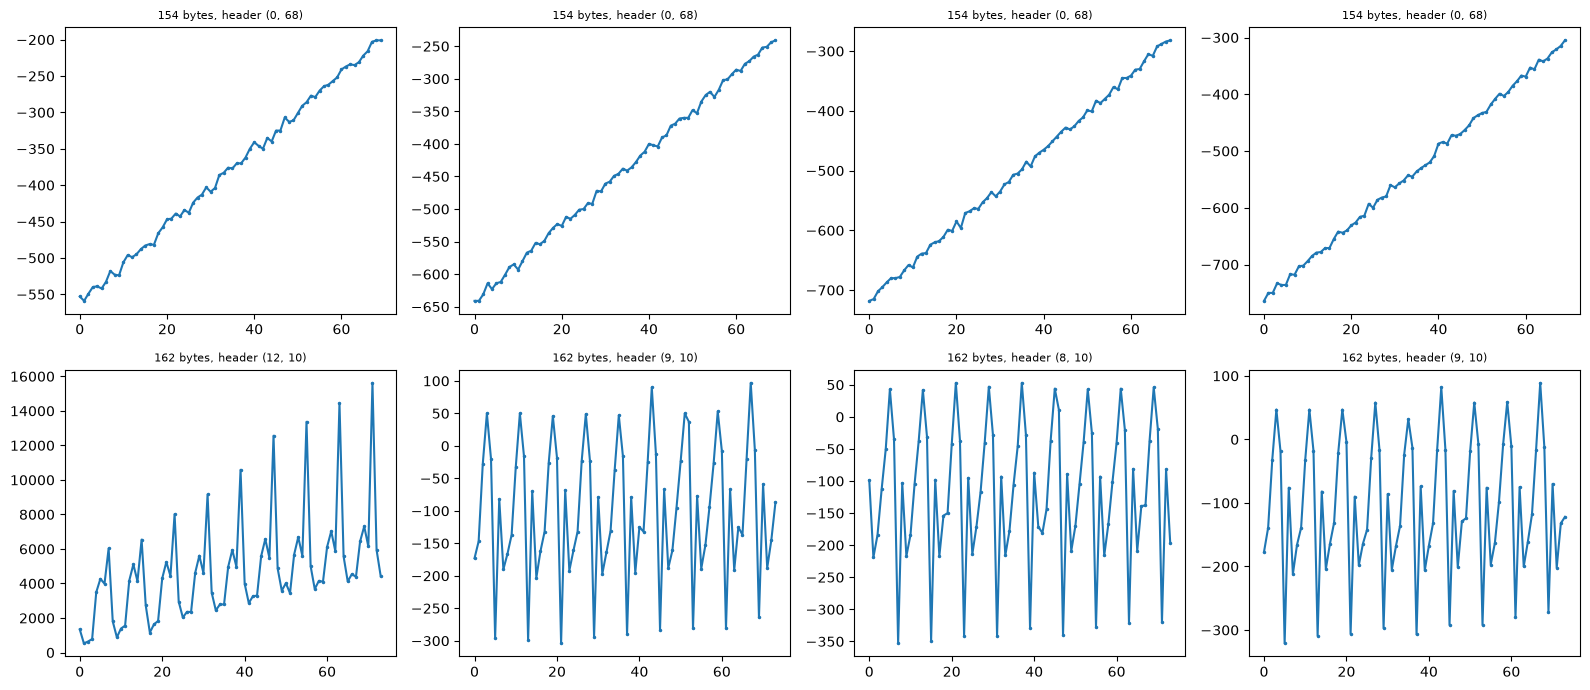

In [68]:
def samples(chunk: bytes) -> np.ndarray:
    return np.frombuffer(chunk[2 * HEADER_WORDS : -CRC_LEN], dtype=">i2")


fig, axes = plt.subplots(len(CHUNK_SIZES), 4, figsize=(16, 3.5 * len(CHUNK_SIZES)))
for row, size in enumerate(CHUNK_SIZES):
    selection = [chunk for _, _, _, _, chunk in chunks if len(chunk) == size][::97][:4]
    for ax, chunk in zip(axes[row], selection, strict=False):
        ax.plot(samples(chunk), ".-", markersize=3)
        ax.set_title(f"{size} bytes, header {header(chunk)[1:3]}", fontsize=8)
fig.tight_layout()
plt.show()

### Stitching chunks

If chunks continue each other, a run of consecutive packets is one long time series. For each chunk size take the
run with the most chunks of that size and plot the first ones.

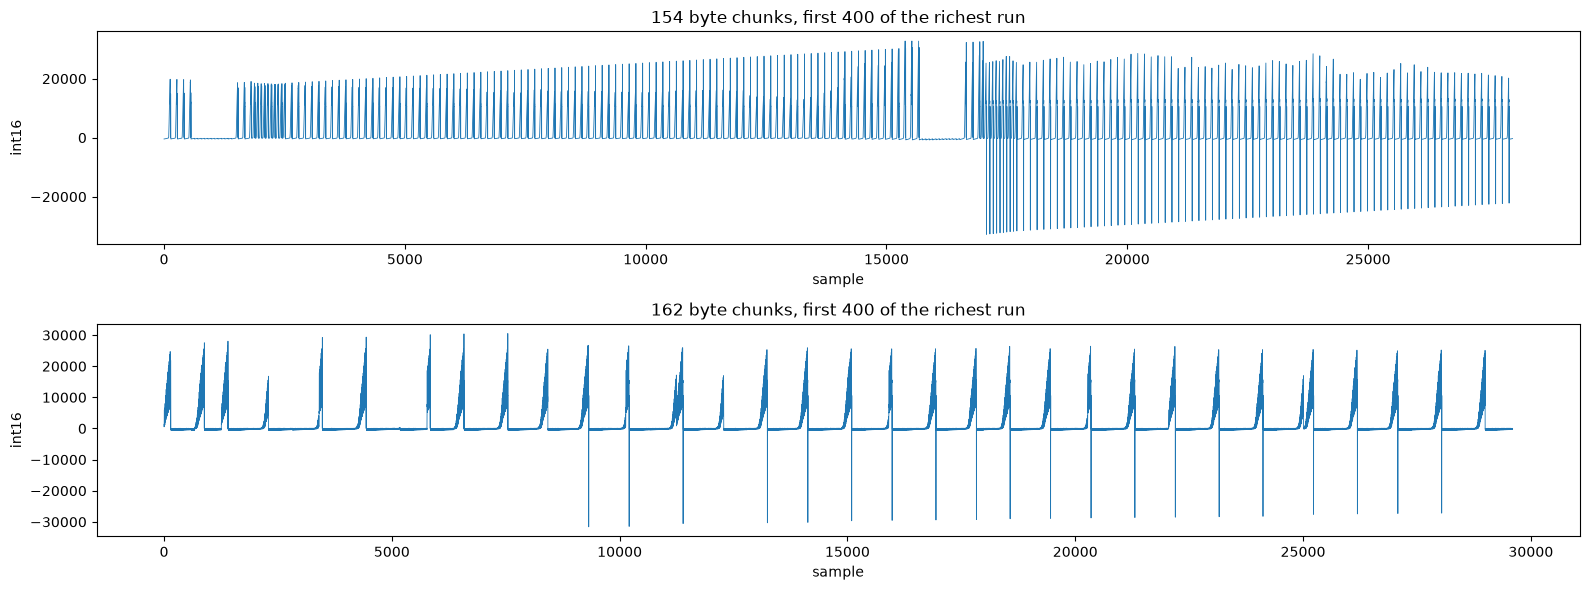

In [69]:
STITCH_CHUNKS = 400

run_samples: dict[tuple[str, int], dict[int, list[np.ndarray]]] = {}  # run -> chunk size -> samples per chunk
for key, run in runs.items():
    by_size = defaultdict(list)
    for _, _, packet in run:
        data = packet[DATA_OFFSET:-CRC_LEN]
        for offset in find_chunks(data):
            chunk = data[offset : offset + int.from_bytes(data[offset : offset + 2])]
            by_size[len(chunk)].append(samples(chunk))
    run_samples[key] = by_size


def stitched(size: int, limit: int = STITCH_CHUNKS) -> np.ndarray:
    """Samples of the first chunks of one size, from the run which has the most of them."""
    best_run = max(run_samples.values(), key=lambda by_size: len(by_size[size]))
    return np.concatenate(best_run[size][:limit]).astype(np.float64)


fig, axes = plt.subplots(len(CHUNK_SIZES), 1, figsize=(16, 3 * len(CHUNK_SIZES)))
for ax, size in zip(axes, CHUNK_SIZES, strict=True):
    ax.plot(stitched(size), linewidth=0.6)
    ax.set(title=f"{size} byte chunks, first {STITCH_CHUNKS} of the richest run", xlabel="sample", ylabel="int16")
fig.tight_layout()
plt.show()

## 6. Channel structure and sample rate

The 162 byte chunks showed a pattern with a period of 8 samples. If 8 channels are multiplexed, the series at lag 8
is smooth and the one at lag 1 is not. Compare the mean absolute step between samples that are `lag` apart in a
stitched stream (headers and CRCs cut out).

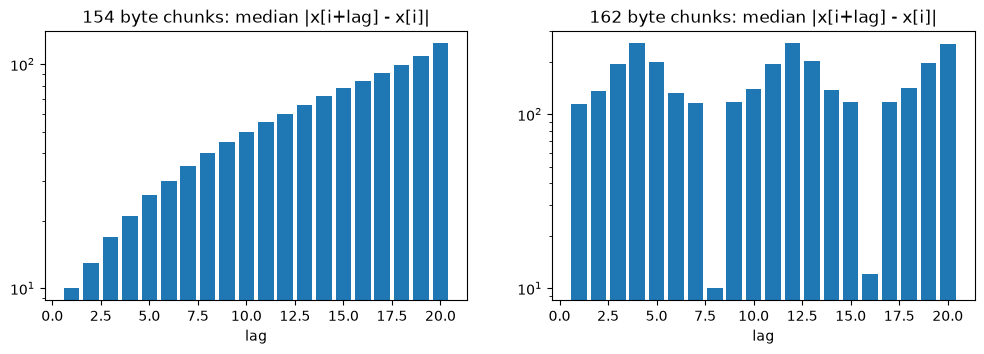

In [70]:
MAX_LAG = 20

fig, axes = plt.subplots(1, len(CHUNK_SIZES), figsize=(12, 3.5))
for ax, size in zip(axes, CHUNK_SIZES, strict=True):
    stream_samples = stitched(size)
    steps_by_lag = [np.median(np.abs(stream_samples[lag:] - stream_samples[:-lag])) for lag in range(1, MAX_LAG + 1)]
    ax.bar(range(1, MAX_LAG + 1), steps_by_lag)
    ax.set(title=f"{size} byte chunks: median |x[i+lag] - x[i]|", xlabel="lag", yscale="log")
plt.show()

## 7. Sample rate

Samples per second of the data, using one packet per tick and the 1 s tick.

In [71]:
per_tick = Counter()
for name, vcid, tick, _, chunk in chunks:
    per_tick[name, vcid, tick, len(chunk)] += len(samples(chunk))
rates = defaultdict(list)
for (_, _, _, size), count in per_tick.items():
    rates[size].append(count / SECONDS_PER_TICK)
for size, values in rates.items():
    print(
        f"{size} byte chunks: median {np.median(values):.0f} samples/s over the ticks that have them ({len(values)})"
    )
print(f"-> {np.median(rates[162]) / 8:.0f} samples/s per channel for the 8 channel stream")

154 byte chunks: median 140 samples/s over the ticks that have them (6319)
162 byte chunks: median 592 samples/s over the ticks that have them (4372)
-> 74 samples/s per channel for the 8 channel stream


### Channels of the 162 byte stream

The samples of consecutive 162 byte chunks continue each other without a gap (the headers and CRCs are not part of the
sample stream): 74 samples per chunk is 9 frames of 8 plus 2, so the channel of the first sample of a chunk moves
back by 2 every chunk (7, 5, 3, 1, 7, ...), which is what the big channel did in the chunk plots. Index word 1 counts
chunks 0 to 13 and tells whether a chunk is missing. Cut the longest stretch without a missing chunk into frames of
8 channels.

444 frames; the sum of the channels drops from high to low after frames [ 92 221 351]
frames between drops: [129 130]


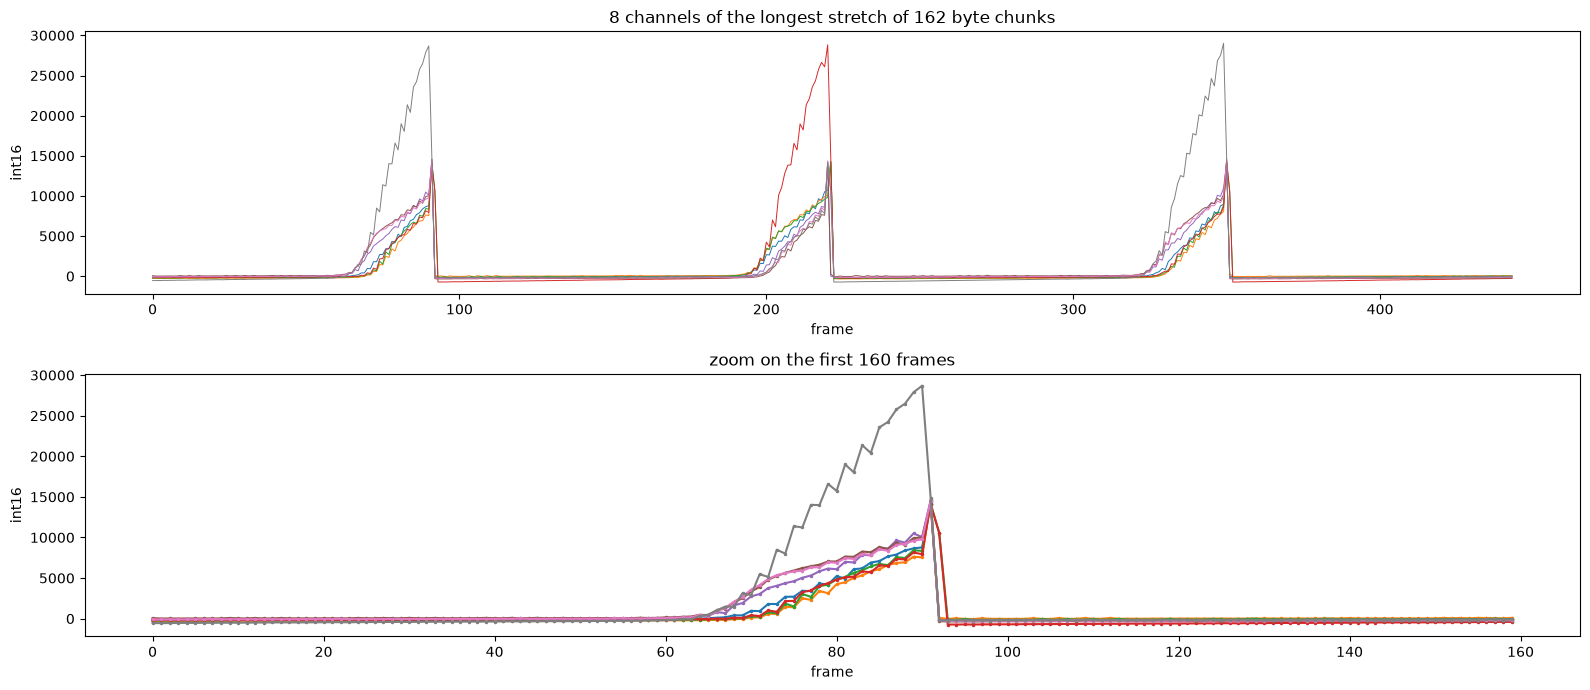

In [72]:
SIZE_8 = 162
INDEX_MODULO = 14  # header word 1 of the 162 byte chunks counts 0 to 13


def channel_stream() -> np.ndarray:
    """Samples of the longest stretch of consecutive 162 byte chunks, as rows of 8 channels."""
    best: list[np.ndarray] = []
    for run in runs.values():
        segment: list[np.ndarray] = []
        previous = None
        for _, _, packet in run:
            data = packet[DATA_OFFSET:-CRC_LEN]
            for offset in find_chunks(data):
                chunk = data[offset : offset + int.from_bytes(data[offset : offset + 2])]
                if len(chunk) != SIZE_8:
                    continue
                index = header(chunk)[1]
                if previous is not None and (index - previous) % INDEX_MODULO != 1:
                    segment = []  # a chunk is missing: the channel phase is lost
                previous = index
                segment.append(samples(chunk))
                if len(segment) > len(best):
                    best = list(segment)
    flat = np.concatenate(best)
    return flat[: len(flat) // 8 * 8].reshape(-1, 8).astype(np.float64)


frames = channel_stream()
total = frames.sum(axis=1)
falls = np.nonzero((total[:-1] > 20000) & (total[1:] < 5000))[0]
print(f"{len(frames)} frames; the sum of the channels drops from high to low after frames {falls}")
print("frames between drops:", np.diff(falls))

fig, (ax_all, ax_zoom) = plt.subplots(2, 1, figsize=(16, 7))
ax_all.plot(frames, linewidth=0.7)
ax_all.set(title="8 channels of the longest stretch of 162 byte chunks", xlabel="frame", ylabel="int16")
ax_zoom.plot(frames[: min(len(frames), 160)], ".-", markersize=3)
ax_zoom.set(title="zoom on the first 160 frames", xlabel="frame", ylabel="int16")
fig.tight_layout()
plt.show()

All 8 channels sit near zero (-300 to 0), then rise together over about 30 frames, one channel (7 here, 3 in the next
pulse) more than the others and up to 29 000, and fall back at once. The pulse repeats with a fixed period. That is
not the Sun's irradiance: it is a stimulus that is cycled (a calibration source) or a scan.

## 8. Looking for LYRA and the Sun

What the plots say:

* **162 byte chunks:** 8 multiplexed int16 channels at about 74 samples/s each (592 in total per second). Between
  pulses every channel sits at about 0 +- 300; the pulses ramp up together and fall back, with a fixed period of
  129 to 130 frames (about 1.75 s).
* **154 byte chunks:** one channel, 70 samples per chunk, each chunk a clean linear ramp (for example from -550 to
  -200) that restarts at the next chunk. About 140 samples/s.

With the corrected clock (one tick is one second) the per channel rate is below LYRA's maximum cadence of 100 Hz, so
the rate no longer argues against LYRA. What does is the shape: LYRA measures a (nearly) steady irradiance in 4
broad-band channels per unit, and these channels are dark with pulses that rise by 30 000 counts. LYRA does have two
calibration LEDs per detector, and a cycled stimulus is what an LED test would look like, but nothing here shows
which instrument it is. To decide: compare with a LYRA file for the same dates (see the GPS dates in
`APID_18.ipynb`, August to October 2025) or read the ICD. It holds nothing about the position of the Sun.

## What we know so far

* APID 22 is 11 170 packets with the same header as the APID 2 reports (secondary header `10 08 8e`, marker, tick
  counter, 2 byte data length at 21, data from 23, CRC-16/CCITT over the whole packet at the end). One packet per
  second (tick), 99.3 % of the time.
* The data field is a series of self-describing chunks of 154 or 162 bytes: size, index, a type word, a 16 bit
  counter (+14 per chunk), a source id (49 or 50), flags, 70 or 74 samples, and a CRC-16 of the chunk. The first
  chunk of a packet starts at offset 0 in about half the packets and in the middle of a chunk in the others.
* The samples are int16. The 162 byte chunks are one continuous stream of 8 interleaved channels, about 74 samples/s
  each; the 154 byte chunks are a sawtooth, about 140 samples/s.
* The 8 channels are dark with a periodic ramp pulse on all of them. **LYRA:** a possible candidate (rate fits, LYRA
  has calibration LEDs) but not confirmed, the shape is not that of a solar irradiance. **Sun position / attitude:**
  not here.